#  Prédiction du Churn Client — Opérateur Télécom

## Contexte
Dans un marché des télécommunications fortement concurrentiel, la fidélisation des clients est un enjeu stratégique. Ce notebook développe un modèle de Machine Learning capable de prédire le risque de churn et d’identifier les facteurs qui influencent cette décision.

## Objectifs
1. Comprendre les facteurs influençant le churn
2. Réaliser une analyse exploratoire des données (EDA)
3. Préparer les données pour le Machine Learning
4. Construire plusieurs modèles de classification
5. Comparer leurs performances
6. Identifier les variables les plus importantes
7. Proposer des recommandations métier pour améliorer la rétention

## Dataset
[Tesco Customer Churn (Kaggle)](https://www.kaggle.com/datasets/blastchar/telco-customer-churn) — 7043 clients, 21 variables

## 0. Imports et configuration

On charge les bibliothèques nécessaires pour la manipulation des données, la visualisation et le machine learning.

In [64]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, roc_curve, confusion_matrix, classification_report)
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
import shap
import warnings

warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', context='talk', palette='Set2')
plt.rcParams.update({
    'figure.figsize': (10, 6),
    'axes.titleweight': 'bold',
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'legend.fontsize': 10,
})

RANDOM_STATE = 42

## Étape 1 — Chargement et compréhension des données

On charge le dataset et on inspecte sa structure : dimensions, types de variables, valeurs manquantes et éventuelles anomalies.

In [65]:
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
print("Dimensions :", df.shape)
df.head()

Dimensions : (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Étape 2 — Vérification des types et des valeurs manquantes

On inspecte le schéma du dataset pour repérer les colonnes à transformer avant la modélisation.

In [66]:

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## Étape 3 — Nettoyage des colonnes numériques

La colonne `TotalCharges` est stockée en texte dans le dataset. On la convertit en numérique afin de pouvoir l’exploiter correctement dans les modèles.

In [67]:
# TotalCharges est stocké en texte : on le convertit en numérique
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print(df.isnull().sum()[df.isnull().sum() > 0])

TotalCharges    11
dtype: int64


## Étape 4 — Traitement des données manquantes et suppression des identifiants

On complète les valeurs manquantes par 0, puis on retire la colonne `customerID`, qui ne porte pas d’information utile pour la prédiction.

In [68]:
# Les valeurs manquantes correspondent à des clients avec tenure = 0 (nouveaux clients, pas encore facturés)
df['TotalCharges'] = df['TotalCharges'].fillna(0)
df.drop(columns=['customerID'], inplace=True)
print("Doublons :", df.duplicated().sum())

Doublons : 22


## Exploratory Data Analysis (EDA)

Cette section permet de visualiser la distribution du churn et d’identifier les variables les plus discriminantes.

Distribution du churn

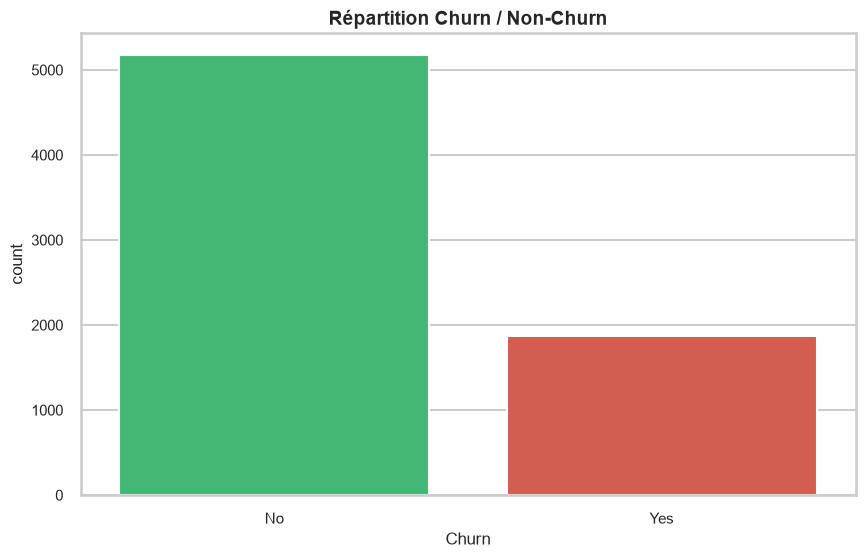

Taux de churn : 26.5%


In [84]:
churn_rate = df['Churn'].value_counts(normalize=True)['Yes'] * 100
sns.countplot(data=df, x='Churn', hue='Churn', palette=['#2ecc71', '#e74c3c'], legend=False)
plt.title('Répartition Churn / Non-Churn')
plt.show()
print(f"Taux de churn : {churn_rate:.1f}%")

 Churn selon le contrat

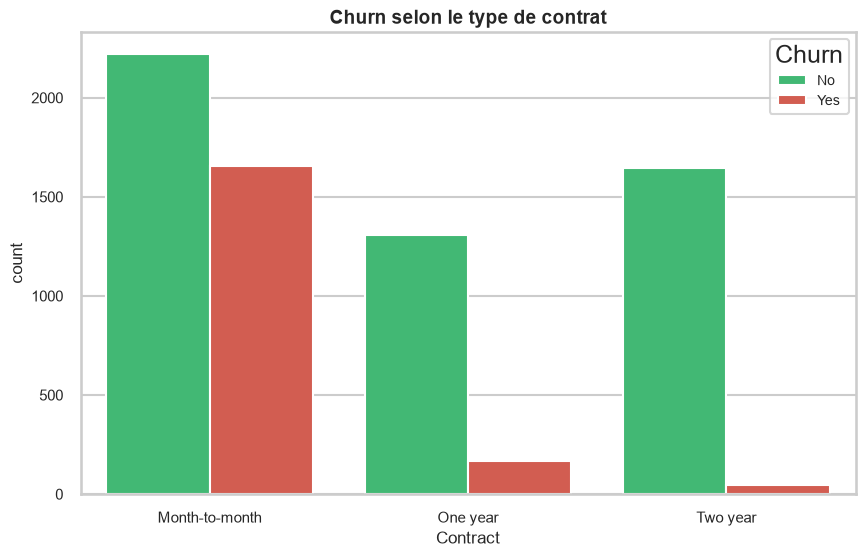

In [85]:
sns.countplot(data=df, x='Contract', hue='Churn', palette=['#2ecc71', '#e74c3c'])
plt.title('Churn selon le type de contrat')
plt.show()

 Churn selon l'ancienneté

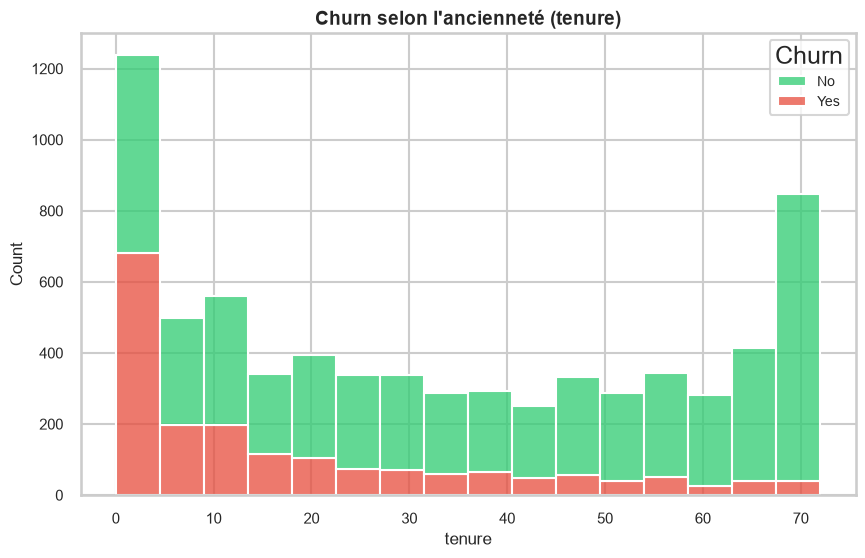

In [86]:
sns.histplot(data=df, x='tenure', hue='Churn', multiple='stack', palette=['#2ecc71', '#e74c3c'])
plt.title("Churn selon l'ancienneté (tenure)")
plt.show()

Charges mensuelles vs churn

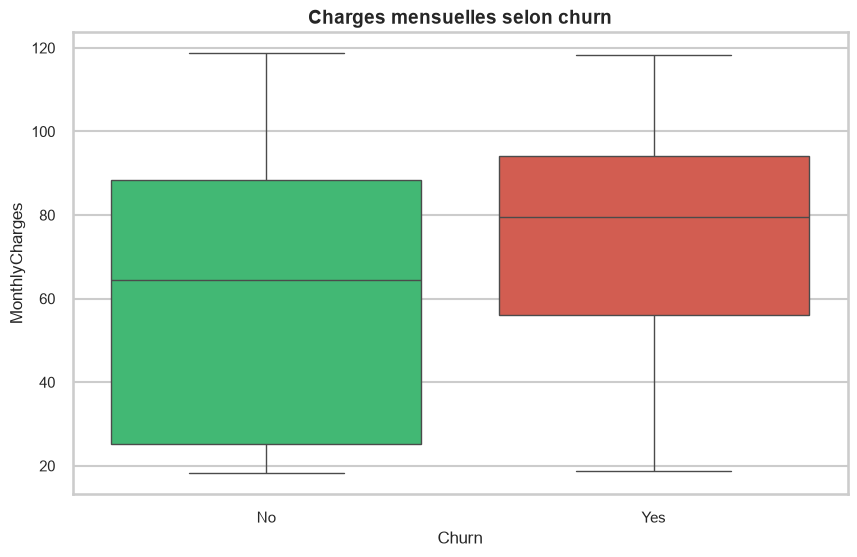

In [87]:
sns.boxplot(data=df, x='Churn', y='MonthlyCharges', hue='Churn', palette=['#2ecc71', '#e74c3c'], legend=False)
plt.title('Charges mensuelles selon churn')
plt.show()

 Corrélations

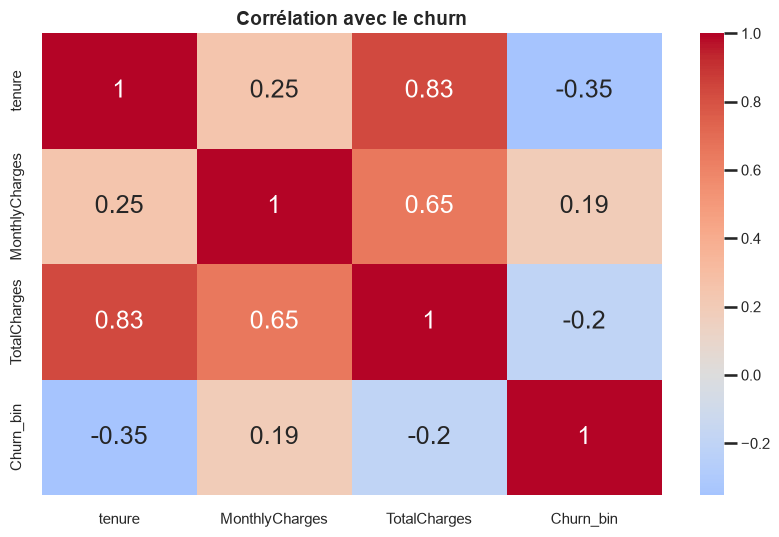

In [88]:
num_df = df[['tenure', 'MonthlyCharges', 'TotalCharges']].copy()
num_df['Churn_bin'] = df['Churn'].map({'Yes': 1, 'No': 0})
sns.heatmap(num_df.corr(), annot=True, cmap='coolwarm', center=0)
plt.title('Corrélation avec le churn')
plt.show()

Préparation des données

 Encodage

In [74]:
df_model = df.copy()
df_model['Churn'] = df_model['Churn'].map({'Yes': 1, 'No': 0})

binary_cols = ['gender', 'Partner', 'Dependents', 'PhoneService', 'PaperlessBilling']
le = LabelEncoder()
for col in binary_cols:
    df_model[col] = le.fit_transform(df_model[col])

multi_cols = ['MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
              'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
              'Contract', 'PaymentMethod']
df_model = pd.get_dummies(df_model, columns=multi_cols, drop_first=True)
df_model.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,...,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,1,29.85,29.85,0,...,False,False,False,False,False,False,False,False,True,False
1,1,0,0,0,34,1,0,56.95,1889.50,0,...,False,False,False,False,False,True,False,False,False,True
2,1,0,0,0,2,1,1,53.85,108.15,1,...,False,False,False,False,False,False,False,False,False,True
3,1,0,0,0,45,0,0,42.30,1840.75,0,...,True,False,False,False,False,True,False,False,False,False
4,0,0,0,0,2,1,1,70.70,151.65,1,...,False,False,False,False,False,False,False,False,True,False


## Étape 5 — Préparation des données pour le modèle

On prépare une version du dataset adaptée à l’apprentissage supervisé, en codant les variables catégorielles et en définissant la cible.

Split train/test

In [75]:
X = df_model.drop(columns=['Churn'])
y = df_model['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print(X_train.shape, X_test.shape)

(5634, 30) (1409, 30)


Normalisation

In [ ]:
num_features = ['tenure', 'MonthlyCharges', 'TotalCharges']
scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[num_features] = scaler.fit_transform(X_train[num_features])
X_test_scaled[num_features] = scaler.transform(X_test[num_features])

 SMOTE (rééquilibrage)

In [77]:
smote = SMOTE(random_state=RANDOM_STATE)
X_train_bal, y_train_bal = smote.fit_resample(X_train_scaled, y_train)
print("Avant :", y_train.value_counts().to_dict())
print("Après :", y_train_bal.value_counts().to_dict())

Avant : {0: 4139, 1: 1495}
Après : {0: 4139, 1: 4139}


 Entraîner les 4 modèles

In [78]:
models = {
    'Régression Logistique': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    'Decision Tree': DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=300, max_depth=10, random_state=RANDOM_STATE),
    'XGBoost': XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.05,
                              eval_metric='logloss', random_state=RANDOM_STATE)
}

trained_models = {}
for name, model in models.items():
    model.fit(X_train_bal, y_train_bal)
    trained_models[name] = model
    print(f"{name} entraîné.")

Régression Logistique entraîné.
Decision Tree entraîné.
Random Forest entraîné.
XGBoost entraîné.


Comparaison des performances

 Tableau de métriques

In [79]:
results = []
for name, model in trained_models.items():
    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]
    results.append({
        'Modèle': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba)
    })

results_df = pd.DataFrame(results).set_index('Modèle').round(3)
results_df.sort_values('ROC-AUC', ascending=False)

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Modèle,,,,,
Random Forest,0.752,0.523,0.749,0.616,0.840
Decision Tree,0.748,0.517,0.783,0.623,0.831
XGBoost,0.752,0.523,0.719,0.606,0.827
Régression Logistique,0.731,0.495,0.698,0.579,0.822


Graphique comparatif

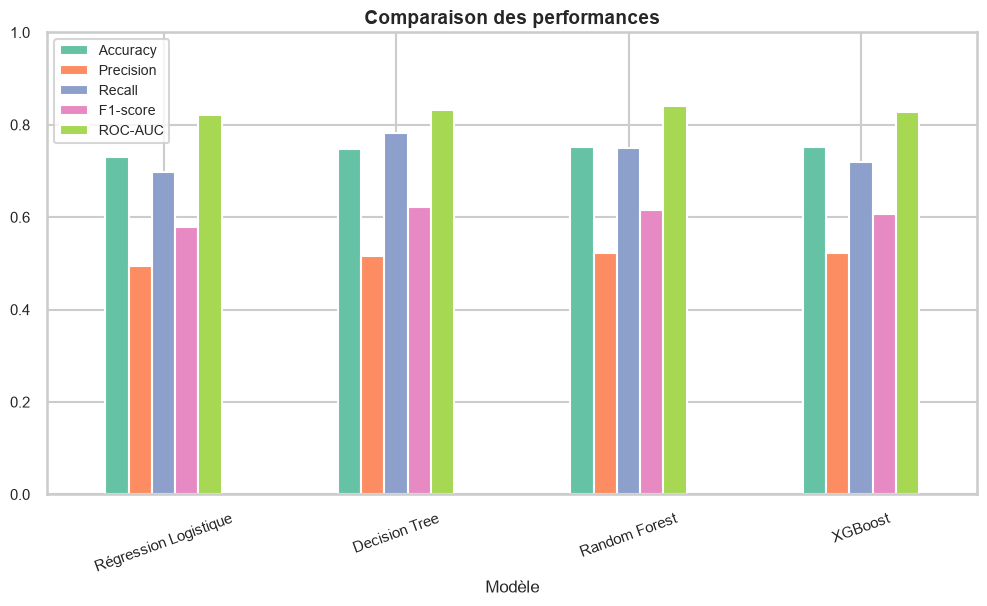

In [80]:
results_df.plot(kind='bar', figsize=(12, 6))
plt.title('Comparaison des performances')
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.show()

Courbes ROC

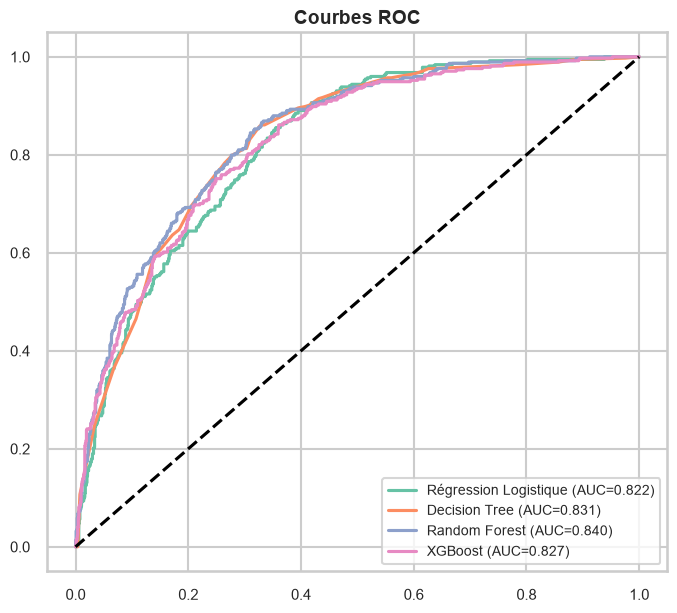

In [81]:
plt.figure(figsize=(8, 7))
for name, model in trained_models.items():
    y_proba = model.predict_proba(X_test_scaled)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    plt.plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})')
plt.plot([0,1],[0,1],'k--')
plt.legend()
plt.title('Courbes ROC')
plt.show()

Meilleur modèle

In [82]:
best_model_name = results_df['ROC-AUC'].idxmax()
best_model = trained_models[best_model_name]
print("Meilleur modèle :", best_model_name)
print(classification_report(y_test, best_model.predict(X_test_scaled)))

Meilleur modèle : Random Forest
              precision    recall  f1-score   support

           0       0.89      0.75      0.82      1035
           1       0.52      0.75      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.79      0.75      0.76      1409



### Variables les plus importantes

On visualise les 15 variables qui influencent le plus les prédictions du meilleur modèle.

In [ ]:
importances = pd.Series(best_model.feature_importances_, index=X_train.columns)
importances.sort_values(ascending=False).head(15).sort_values().plot(kind='barh', figsize=(10,8))
plt.title(f'Top 15 variables — {best_model_name}')
plt.show()

 SHAP

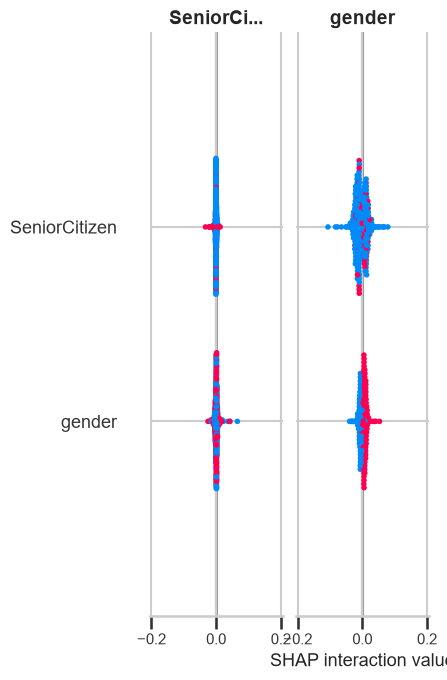

In [83]:
explainer = shap.TreeExplainer(best_model)
X_sample = X_test_scaled.sample(500, random_state=RANDOM_STATE)
shap_values = explainer.shap_values(X_sample)
sv = shap_values[1] if isinstance(shap_values, list) else shap_values
shap.summary_plot(sv, X_sample)